# A Simple Pay Equity Regression (SIMULATED example company)

**Important: every employee below is simulated.** There is no real company or person here.
I created the data on purpose, with pay gaps built in at known sizes, so we can check that
the regression finds them. Real engagements use a client's confidential HR data.

**The scenario.** "A company asks: do we pay women, or employees of a given race or
ethnicity, less than comparable colleagues?"

**The method.** Multiple linear regression (often called multivariate regression in HR work):

    Pay = b0 + b1*Female + b2*Black + b3*Hispanic + b4*Asian + b5*Age40Plus
              + b6*Experience + b7*Tenure + b8*Education + location + department + job level + error

Each coefficient (b) is a *slope*: how many dollars pay changes when that variable goes up by
one unit, holding everything else in the model equal. For a 0/1 flag such as Female, "one unit"
means going from 0 to 1, so the slope is the pay gap between the two groups.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

os.makedirs("images", exist_ok=True)
rng = np.random.default_rng(42)
N = 2000

## Step 1. Simulate the company

The pay formula below is the "truth" that the regression will try to recover. The built-in
pay gaps, holding everything else equal, are: **women -$3,500, Black employees -$3,000,
Hispanic employees -$2,000, Asian employees $0, age 40+ $0.**

I also make women and minority employees somewhat less likely to reach the higher job levels.
This is realistic and is why the raw gap ends up bigger than the built-in one.

In [2]:
female   = rng.random(N) < 0.47
race     = rng.choice(["White", "Black", "Hispanic", "Asian"], size=N, p=[0.58, 0.13, 0.17, 0.12])
age      = np.clip(rng.normal(40, 10, N), 22, 64).round()
experience = np.clip(age - 22 - rng.normal(1, 2, N), 0, None).round()          # years of work before/at hire
tenure   = np.round(rng.uniform(0.1, 1.0, N) * np.minimum(experience, 20), 1)   # years at this company
education = rng.choice([1, 2, 3, 4], size=N, p=[0.20, 0.50, 0.25, 0.05])        # 1 HS, 2 Bachelor's, 3 Master's, 4 PhD
location = rng.choice(["High-cost", "Mid-cost", "Low-cost"], size=N, p=[0.30, 0.40, 0.30])
dept     = rng.choice(["Engineering", "Sales", "Operations", "Corporate"], size=N, p=[0.30, 0.25, 0.30, 0.15])

# Job level (1 to 5): driven by experience, tenure and education, but women and minority
# employees are somewhat less likely to reach higher levels.
latent = (0.08 * experience + 0.06 * tenure + 0.35 * (education - 1) + rng.normal(0, 1, N)
          - 0.55 * female - 0.45 * (race == "Black") - 0.35 * (race == "Hispanic"))
level = pd.cut(latent, bins=np.quantile(latent, [0, 0.30, 0.60, 0.80, 0.93, 1.0]),
               labels=[1, 2, 3, 4, 5], include_lowest=True).astype(int)

loc_prem  = pd.Series(location).map({"High-cost": 8000, "Mid-cost": 3500, "Low-cost": 0}).values
dept_prem = pd.Series(dept).map({"Engineering": 6000, "Sales": 2000, "Operations": 0, "Corporate": 1500}).values

pay = (42000 + 8500 * (level - 1) + 700 * experience + 900 * tenure + 2500 * (education - 1)
       + loc_prem + dept_prem
       - 3500 * female - 3000 * (race == "Black") - 2000 * (race == "Hispanic")   # built-in pay gaps
       + rng.normal(0, 5000, N))                                                  # everything we cannot see

df = pd.DataFrame({
    "Gender": np.where(female, "Female", "Male"), "Race": race, "Age": age.astype(int),
    "Age40Plus": (age >= 40).astype(int), "Experience": experience, "Tenure": tenure,
    "Education": education, "Location": location, "Dept": dept, "JobLevel": level,
    "Pay": pay.round(0)})
df["Female"] = (df["Gender"] == "Female").astype(int)
df.to_csv("simulated_company_pay_data.csv", index=False)
df.head()

,Gender,Race,Age,Age40Plus,Experience,Tenure,Education,Location,Dept,JobLevel,Pay,Female
0,Male,Hispanic,30,0,6.0,4.6,3,Mid-cost,Corporate,2,71536.0,0
1,Female,White,25,0,0.0,0.0,3,Mid-cost,Corporate,2,61000.0,1
2,Male,Asian,54,1,28.0,14.6,2,Mid-cost,Corporate,5,113291.0,0
3,Male,Black,64,1,41.0,2.5,2,Mid-cost,Sales,4,109079.0,0
4,Female,White,35,0,11.0,3.7,2,Mid-cost,Operations,2,68046.0,1


## Step 2. Look before modelling: the raw gaps and who sits where

In [3]:
print(f"Employees: {len(df)}   Women: {df['Female'].mean():.0%}")
print("\nAverage pay by gender:")
print(df.groupby("Gender")["Pay"].mean().round(0).to_string())
print("\nAverage pay by race/ethnicity:")
print(df.groupby("Race")["Pay"].mean().round(0).to_string())

print("\nShare of each group at job levels 4 and 5 (the best-paid levels):")
senior = df.assign(Senior=df["JobLevel"] >= 4)
print((senior.groupby("Gender")["Senior"].mean() * 100).round(1).to_string())
print((senior.groupby("Race")["Senior"].mean() * 100).round(1).to_string())

Employees: 2000   Women: 47%

Average pay by gender:
Gender
Female    76110.0
Male      83502.0

Average pay by race/ethnicity:
Race
Asian       84790.0
Black       73963.0
Hispanic    76904.0
White       81252.0

Share of each group at job levels 4 and 5 (the best-paid levels):
Gender
Female    13.9
Male      25.5
Race
Asian       25.5
Black       11.5
Hispanic    15.5
White       22.0


## Step 3. Three regression models

Same idea as before: start simple and add one block of controls at a time.

* **Model 1** compares by gender and race only (the raw gaps).
* **Model 2** adds legitimate job-related factors: experience, tenure, education, location,
  department, plus age 40+ (a protected characteristic we also want to test).
* **Model 3** adds job level.

`White` is the reference race and `Male` is the reference gender, so the Female coefficient reads
"compared with comparable men" and each race coefficient reads "compared with comparable White
employees of the same gender".

In [4]:
race_term = "C(Race, Treatment('White'))"
formulas = {
    "Model 1: gender and race only":
        f"Pay ~ Female + {race_term}",
    "Model 2: + experience, tenure, education, location, department, age 40+":
        f"Pay ~ Female + {race_term} + Age40Plus + Experience + Tenure + Education + C(Location) + C(Dept)",
    "Model 3: + job level":
        f"Pay ~ Female + {race_term} + Age40Plus + Experience + Tenure + Education + C(Location) + C(Dept) + C(JobLevel)",
}
fits = {name: smf.ols(f, data=df).fit(cov_type="HC3") for name, f in formulas.items()}

In [5]:
names = {"Female": "Female", f"{race_term}[T.Black]": "Black", f"{race_term}[T.Hispanic]": "Hispanic",
         f"{race_term}[T.Asian]": "Asian", "Age40Plus": "Age 40+"}
rows = []
for model, m in fits.items():
    ci = m.conf_int()
    for term, label in names.items():
        if term in m.params:
            rows.append({"model": model[:7], "group": label, "gap_usd": m.params[term],
                         "ci_low": ci.loc[term, 0], "ci_high": ci.loc[term, 1], "p_value": m.pvalues[term]})
res = pd.DataFrame(rows)
res["significant"] = res["p_value"] < 0.05
print(res.round(3).to_string(index=False))
print("\nR-squared (share of pay differences explained):")
for name, m in fits.items():
    print(f"  {name[:7]}: {m.rsquared:.2f}")

truth = {"Female": -3500, "Black": -3000, "Hispanic": -2000, "Asian": 0, "Age 40+": 0}
print("\nBuilt-in (true) gaps:", truth)

  model    group   gap_usd    ci_low   ci_high  p_value  significant
Model 1   Female -7313.789 -9062.714 -5564.864    0.000         True
Model 1    Black -7220.434 -9808.123 -4632.745    0.000         True
Model 1 Hispanic -4298.967 -6691.474 -1906.461    0.000         True
Model 1    Asian  3419.198   529.016  6309.379    0.020         True
Model 2   Female -7110.692 -7920.446 -6300.937    0.000         True
Model 2    Black -6618.381 -7763.673 -5473.089    0.000         True
Model 2 Hispanic -4129.717 -5244.049 -3015.384    0.000         True
Model 2    Asian   452.547  -894.600  1799.694    0.510        False
Model 2  Age 40+   623.425  -764.654  2011.504    0.379        False
Model 3   Female -3511.242 -3973.429 -3049.056    0.000         True
Model 3    Black -3060.693 -3743.201 -2378.186    0.000         True
Model 3 Hispanic -1497.019 -2109.689  -884.349    0.000         True
Model 3    Asian   296.358  -425.983  1018.699    0.421        False
Model 3  Age 40+   129.439  -602.2

**How to read the table**
* `gap_usd` is the coefficient: the pay difference in dollars versus comparable colleagues in the
  reference group (men for gender, White employees for race). Negative means paid less.
* `ci_low` / `ci_high` is the 95% range. If it contains 0, we can't tell the gap from chance.
* `p_value` below 0.05 means statistically significant.
* R-squared is the share of pay differences the model explains.

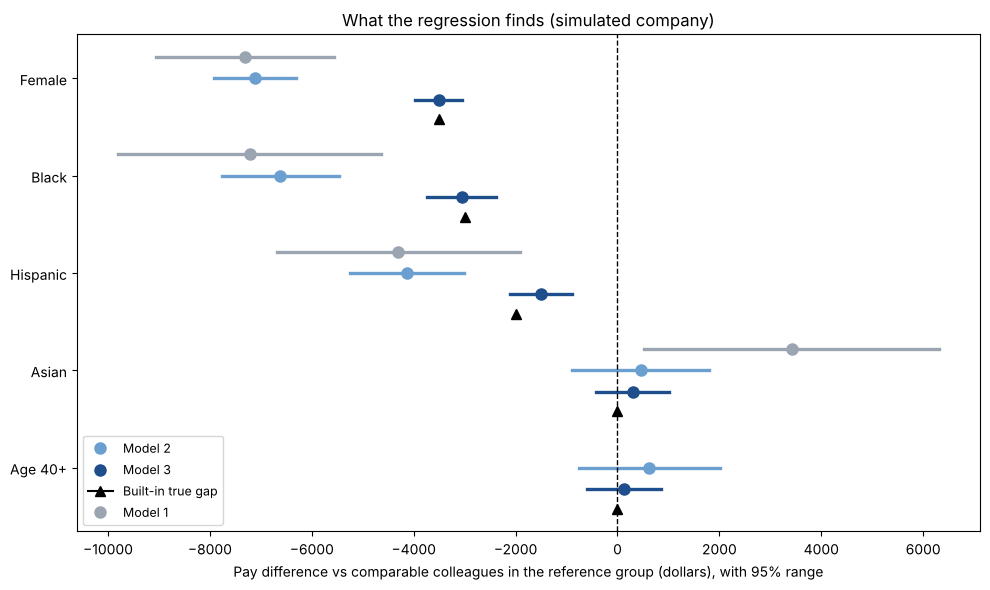

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
groups = ["Female", "Black", "Hispanic", "Asian", "Age 40+"]
colors = {"Model 1": "#9AA5B1", "Model 2": "#6A9FD0", "Model 3": "#1F4E8C"}
offset = {"Model 1": 0.22, "Model 2": 0.0, "Model 3": -0.22}
seen = set()
for gi, g in enumerate(groups[::-1]):
    for mk in colors:
        sub = res[(res["group"] == g) & (res["model"] == mk)]
        if sub.empty:              # Age 40+ is not in Model 1
            continue
        r = sub.iloc[0]
        y = gi + offset[mk]
        ax.plot([r.ci_low, r.ci_high], [y, y], color=colors[mk], lw=2.4)
        ax.plot(r.gap_usd, y, "o", color=colors[mk], markersize=8,
                label=mk if mk not in seen else None, zorder=3)
        seen.add(mk)
    ax.plot(truth[g], gi - 0.42, marker="^", color="black", markersize=7,
            label="Built-in true gap" if "truth" not in seen else None)
    seen.add("truth")
ax.axvline(0, color="black", ls="--", lw=1)
ax.set_yticks(range(len(groups))); ax.set_yticklabels(groups[::-1])
ax.set_xlabel("Pay difference vs comparable colleagues in the reference group (dollars), with 95% range")
ax.set_title("What the regression finds (simulated company)")
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.savefig("images/01_regression_results.png", dpi=150); plt.show()

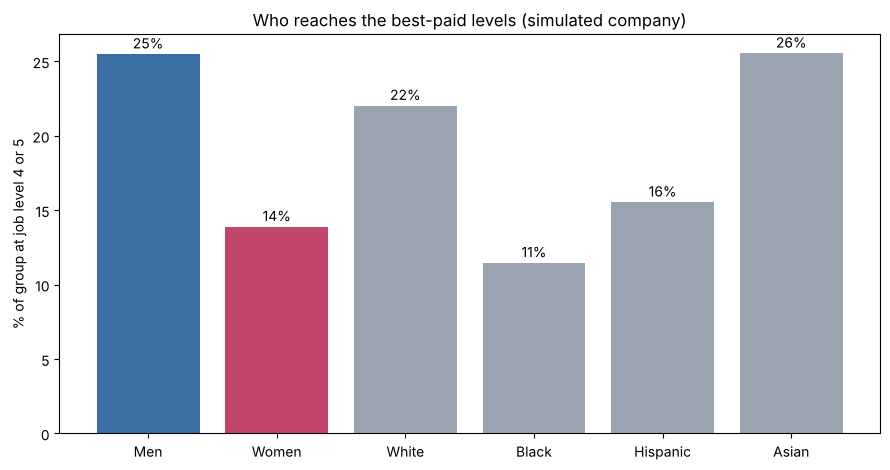

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.8))
groups_sen = {"Men": df["Gender"] == "Male", "Women": df["Gender"] == "Female",
              "White": df["Race"] == "White", "Black": df["Race"] == "Black",
              "Hispanic": df["Race"] == "Hispanic", "Asian": df["Race"] == "Asian"}
share = {k: (df.loc[v, "JobLevel"] >= 4).mean() * 100 for k, v in groups_sen.items()}
bars = ax.bar(list(share), list(share.values()), color=["#3A6EA5", "#C2456B", "#9AA5B1", "#9AA5B1", "#9AA5B1", "#9AA5B1"])
for b, v in zip(bars, share.values()):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.4, f"{v:.0f}%", ha="center")
ax.set_ylabel("% of group at job level 4 or 5")
ax.set_title("Who reaches the best-paid levels (simulated company)")
plt.tight_layout(); plt.savefig("images/02_who_reaches_senior_levels.png", dpi=150); plt.show()